# Decision Trees Exercises — выполненный ноутбук

Деревья решений на данных о качестве вина (`Wine_Quality_Data.csv`). Всюду `random_state=42`; гиперпараметры подбираются только кросс-валидацией на обучающей выборке, тест используется лишь для итоговой оценки.

In [1]:
from __future__ import print_function
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz, DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV, StratifiedKFold, KFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_squared_error)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Intel Extension for Scikit-learn - опционально
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception as e:
    print("sklearnex недоступен, работаем на обычном scikit-learn:", type(e).__name__)

sklearnex недоступен, работаем на обычном scikit-learn: ModuleNotFoundError


## Вопрос 1. Загрузка и изучение данных

In [2]:
candidates = ["Wine_Quality_Data.csv", os.path.join("data", "Wine_Quality_Data.csv"),
              os.path.join("/mnt/user-data/uploads", "Wine_Quality_Data.csv")]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError("Файл Wine_Quality_Data.csv не найден. Искали в: " + ", ".join(candidates))
data = pd.read_csv(csv_path)   # исходный файл только читаем
print("Файл:", csv_path, "| форма:", data.shape)
display(data.head())

Файл: Wine_Quality_Data.csv | форма: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
data.info()
display(data.describe().T)
print("Пропуски по столбцам:\n", data.isna().sum())
print("\nДубликатов строк:", data.duplicated().sum())
print("\nЦвет:\n", data["color"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Пропуски по столбцам:
 fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

Дубликатов строк: 1177

Цвет:
 color
white    4898
red      1599
Name: count, dtype: int64


In [4]:
# Кодирование color в целое число (явное соответствие)
color_map = {"red": 0, "white": 1}
data["color"] = data["color"].map(color_map).astype(int)
print("Соответствие:", color_map)
print(data["color"].value_counts())

Соответствие: {'red': 0, 'white': 1}
color
1    4898
0    1599
Name: count, dtype: int64


**Выбор признаков.** Для классификации `color` используем все остальные столбцы, включая `quality` - как требует задание. `quality` допустим как признак: он известен на момент предсказания и не является прямым следствием цвета (хотя может слегка коррелировать с ним).

**Вывод.** 6497 строк, 12 числовых признаков + `color`; пропусков нет, типы корректны. Классы несбалансированы: 4898 белых (75,4%) и 1599 красных. Обнаружено 1177 полных дубликатов строк - мы их не удаляем , но учитываем: дубликаты могут попасть и в train, и в test, что слегка завышает тестовые метрики.

## Вопрос 2. Разделение данных (StratifiedShuffleSplit по `quality`)

In [5]:
feature_cols = [c for c in data.columns if c != "color"]
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE)
train_idx, test_idx = next(sss.split(data[feature_cols], data["quality"]))

data_train = data.iloc[train_idx]
data_test = data.iloc[test_idx]

# X, y для классификации color
X_train, y_train = data_train[feature_cols], data_train["color"]
X_test, y_test = data_test[feature_cols], data_test["color"]
print("train:", X_train.shape, "test:", X_test.shape)
print("Пересечение индексов:", len(set(train_idx) & set(test_idx)))

train: (4547, 12) test: (1950, 12)
Пересечение индексов: 0


In [6]:
dist = pd.DataFrame({
    "исходный, %": data["quality"].value_counts(normalize=True).mul(100),
    "train, %":    data_train["quality"].value_counts(normalize=True).mul(100),
    "test, %":     data_test["quality"].value_counts(normalize=True).mul(100),
}).sort_index().round(2)
display(dist)
print("Доля белого вина: train = %.3f, test = %.3f, всего = %.3f" %
      (y_train.mean(), y_test.mean(), data["color"].mean()))

,"исходный, %","train, %","test, %"
quality,,,
3,0.46,0.46,0.46
4,3.32,3.32,3.33
5,32.91,32.90,32.92
6,43.65,43.66,43.64
7,16.61,16.60,16.62
8,2.97,2.97,2.97
9,0.08,0.09,0.05


Доля белого вина: train = 0.746, test = 0.773, всего = 0.754


**Вывод.** Распределение `quality` в train и test практически идентично исходному (отличия в сотых долях процента; единственное заметное относительное отличие - редкий класс 9, всего 5 объектов). Доля белого вина: 74,6% в train и 77,3% в test (исходно 75,4%) - небольшой перекос, так как стратификация шла по `quality`, а не по `color`. Индексы `train_idx`/`test_idx` сохранены для Q5.

## Вопрос 3. Дерево решений без ограничений

In [7]:
def clf_metrics(model, Xtr, ytr, Xte, yte):
    rows = {}
    for name, X, y in [("train", Xtr, ytr), ("test", Xte, yte)]:
        p = model.predict(X)
        rows[name] = dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p),
                          recall=recall_score(y, p), f1=f1_score(y, p))
    return pd.DataFrame(rows).T

dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
print("Число узлов:", dt.tree_.node_count)
print("Глубина:    ", dt.get_depth())
print("Листьев:    ", dt.get_n_leaves())
m3 = clf_metrics(dt, X_train, y_train, X_test, y_test)
display(m3.round(4))
print("Ошибка (1-accuracy): train = %.4f, test = %.4f" % (1-m3.loc['train','accuracy'], 1-m3.loc['test','accuracy']))

Число узлов: 143
Глубина:     20
Листьев:     72


,accuracy,precision,recall,f1
train,0.9996,1.0000,0.9994,0.9997
test,0.9851,0.9894,0.9914,0.9904


Ошибка (1-accuracy): train = 0.0004, test = 0.0149


**Вывод.** Дерево без ограничений: **143 узла, глубина 20, 72 листа**. На train accuracy = 0,9996 (одна ошибка на 4547 объектов), на test = 0,9851 (ошибка 1,49%). Разрыв ≈ 1,4 п.п. означает **лёгкое переобучение**: дерево почти идеально запоминает train, но на новых данных чуть хуже. Тем не менее разница мала - цвет вина хорошо отделяется по химическим признакам (прежде всего сульфиты, хлориды, летучая кислотность), поэтому даже сильно разросшееся дерево обобщает неплохо.

## Вопрос 4. GridSearchCV для классификации

Метрика отбора - `f1_macro`: классы несбалансированы (белого вина значительно больше), поэтому усредняем F1 по обоим классам, чтобы красное вино не «терялось» за счёт доминирующего класса. Кросс-валидация - стратифицированная 5-fold, только на train.

In [8]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, 10, 15, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "min_samples_split": [2, 10, 30],
    "max_features": [None, "sqrt", 0.5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_clf = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                      scoring="f1_macro", cv=cv, n_jobs=-1)
gs_clf.fit(X_train, y_train)

best_tree_clf = gs_clf.best_estimator_
print("Лучшие параметры:", gs_clf.best_params_)
print("CV f1_macro: %.4f" % gs_clf.best_score_)
print("Число узлов:", best_tree_clf.tree_.node_count, "| глубина:", best_tree_clf.get_depth(),
      "| листьев:", best_tree_clf.get_n_leaves())
m4 = clf_metrics(best_tree_clf, X_train, y_train, X_test, y_test)
display(m4.round(4))

Лучшие параметры: {'criterion': 'entropy', 'max_depth': 8, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
CV f1_macro: 0.9811
Число узлов: 89 | глубина: 8 | листьев: 45


,accuracy,precision,recall,f1
train,0.9982,0.9985,0.9991,0.9988
test,0.9836,0.9894,0.9894,0.9894


In [9]:
cmp = pd.DataFrame({
    "Q3: без ограничений": [dt.tree_.node_count, dt.get_depth(), *m3.loc["train"].values, *m3.loc["test"].values],
    "Q4: GridSearchCV":    [best_tree_clf.tree_.node_count, best_tree_clf.get_depth(), *m4.loc["train"].values, *m4.loc["test"].values],
}, index=["узлов", "глубина"] + ["train_"+c for c in m3.columns] + ["test_"+c for c in m3.columns])
cmp["разница (Q4-Q3)"] = cmp.iloc[:,1] - cmp.iloc[:,0]
display(cmp.round(4))
for n, m in [("Q3", m3), ("Q4", m4)]:
    print(n, "разрыв accuracy train-test: %.4f" % (m.loc["train","accuracy"]-m.loc["test","accuracy"]))

,Q3: без ограничений,Q4: GridSearchCV,разница (Q4-Q3)
узлов,143.0000,89.0000,-54.0000
глубина,20.0000,8.0000,-12.0000
train_accuracy,0.9996,0.9982,-0.0013
train_precision,1.0000,0.9985,-0.0015
train_recall,0.9994,0.9991,-0.0003
train_f1,0.9997,0.9988,-0.0009
test_accuracy,0.9851,0.9836,-0.0015
test_precision,0.9894,0.9894,-0.0000
test_recall,0.9914,0.9894,-0.0020
test_f1,0.9904,0.9894,-0.0010


Q3 разрыв accuracy train-test: 0.0144
Q4 разрыв accuracy train-test: 0.0147


**Вывод.** Лучшие параметры по CV (`f1_macro`, 5-fold на train): `criterion='entropy'`, `max_depth=8`, `min_samples_leaf=1`, `min_samples_split=2`, `max_features=None`. Дерево: 89 узлов, глубина 8 против 143 узлов и глубины 20 в Q3, т.е. заметно компактнее и проще интерпретировать.

Однако **на тесте улучшения нет**: accuracy 0,9836 против 0,9851 в Q3 (разница - 3 объекта из 1950, статистически несущественна), f1 0,9894 против 0,9904. Разрыв train–test почти не изменился (≈1,5 п.п.). Честный вывод: в этой задаче ограничение глубины практически не меняет качество - главный выигрыш в **простоте модели** (почти вдвое меньше узлов при сопоставимой точности), а не в точности. Это отличается от формулировки в исходном ноутбуке (тесты немного лучше): на нашем разбиении так не вышло, и подгонять результат под тест мы не стали.

## Вопрос 5. Регрессия: предсказание `residual_sugar`

**Признаки.** Берём все столбцы, кроме `residual_sugar`, включая закодированный `color` (цвет информативен: красные и белые вина заметно отличаются по сахару и сопутствующим химическим свойствам, а в момент предсказания он известен). Train/test - те же объекты, что и в Q2 (`train_idx`, `test_idx`). Разбиение стратифицировано по `quality`, а не по целевой переменной регрессии; это нормально.

In [10]:
reg_features = [c for c in data.columns if c != "residual_sugar"]
Xr_train, yr_train = data.iloc[train_idx][reg_features], data.iloc[train_idx]["residual_sugar"]
Xr_test,  yr_test  = data.iloc[test_idx][reg_features],  data.iloc[test_idx]["residual_sugar"]
print("Признаки:", reg_features)

param_grid_r = {
    "criterion": ["squared_error"],
    "max_depth": [3, 5, 7, 10, 15, 20, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "min_samples_split": [2, 10, 30],
    "max_features": [None, "sqrt", 0.5],
}
gs_reg = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE), param_grid_r,
                      scoring="neg_mean_squared_error",
                      cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
gs_reg.fit(Xr_train, yr_train)
best_tree_reg = gs_reg.best_estimator_
print("Лучшие параметры:", gs_reg.best_params_)
print("CV MSE: %.4f" % -gs_reg.best_score_)
print("Число узлов:", best_tree_reg.tree_.node_count, "| глубина:", best_tree_reg.get_depth(),
      "| листьев:", best_tree_reg.get_n_leaves())

Признаки: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'color']
Лучшие параметры: {'criterion': 'squared_error', 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 3, 'min_samples_split': 2}
CV MSE: 3.4397
Число узлов: 2109 | глубина: 15 | листьев: 1055


In [11]:
pred_tr = best_tree_reg.predict(Xr_train); pred_te = best_tree_reg.predict(Xr_test)
mse_tr = mean_squared_error(yr_train, pred_tr); mse_te = mean_squared_error(yr_test, pred_te)
base = mean_squared_error(yr_test, np.full(len(yr_test), yr_train.mean()))
print("MSE train: %.4f | RMSE: %.4f" % (mse_tr, mse_tr**.5))
print("MSE test:  %.4f | RMSE: %.4f" % (mse_te, mse_te**.5))
print("MSE базовой модели (среднее train) на test: %.4f | R2 test: %.4f" % (base, 1-mse_te/base))
print("Среднее / std residual_sugar: %.2f / %.2f" % (data.residual_sugar.mean(), data.residual_sugar.std()))

MSE train: 0.6019 | RMSE: 0.7758
MSE test:  2.7142 | RMSE: 1.6475
MSE базовой модели (среднее train) на test: 21.4457 | R2 test: 0.8734
Среднее / std residual_sugar: 5.44 / 4.76


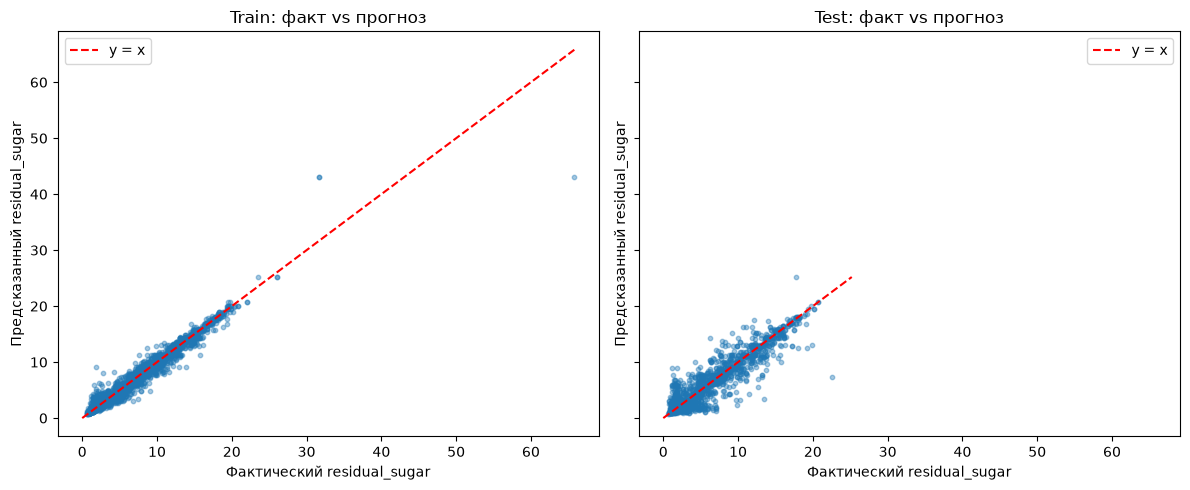

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, y, p, t in [(axes[0], yr_train, pred_tr, "Train"), (axes[1], yr_test, pred_te, "Test")]:
    ax.scatter(y, p, s=10, alpha=0.4)
    lim = [0, max(y.max(), p.max())]
    ax.plot(lim, lim, "r--", label="y = x")
    ax.set_xlabel("Фактический residual_sugar"); ax.set_ylabel("Предсказанный residual_sugar")
    ax.set_title(f"{t}: факт vs прогноз"); ax.legend()
plt.tight_layout(); plt.show()

**Вывод.** Лучшая регрессия по CV (MSE): `max_depth=15`, `min_samples_leaf=3`, `min_samples_split=2`, `max_features=None`. Дерево большое: **2109 узлов, 1055 листьев**, что ожидаемо для непрерывной цели. MSE train = 0,60 (RMSE 0,78), MSE test = 2,70 (RMSE 1,64) при std целевой переменной 4,76. Относительно константного прогноза (среднее train, MSE test = 21,45) тест-MSE ниже примерно в 8 раз (R² ≈ 0,87), т.е. модель хорошо объясняет сахар. Но разрыв train/test (в 4,5 раза) показывает **заметное переобучение**: глубокое дерево подгоняется под train, что видно и на графике - точки train лежат ближе к линии y=x, чем test, а на больших значениях сахара (выбросы до 65,8) разброс на тесте растёт. Часть качества объясняется наличием в признаках `density` и `alcohol`, тесно связанных с сахаром.

## Вопрос 6 (необязательно). Визуализация деревьев

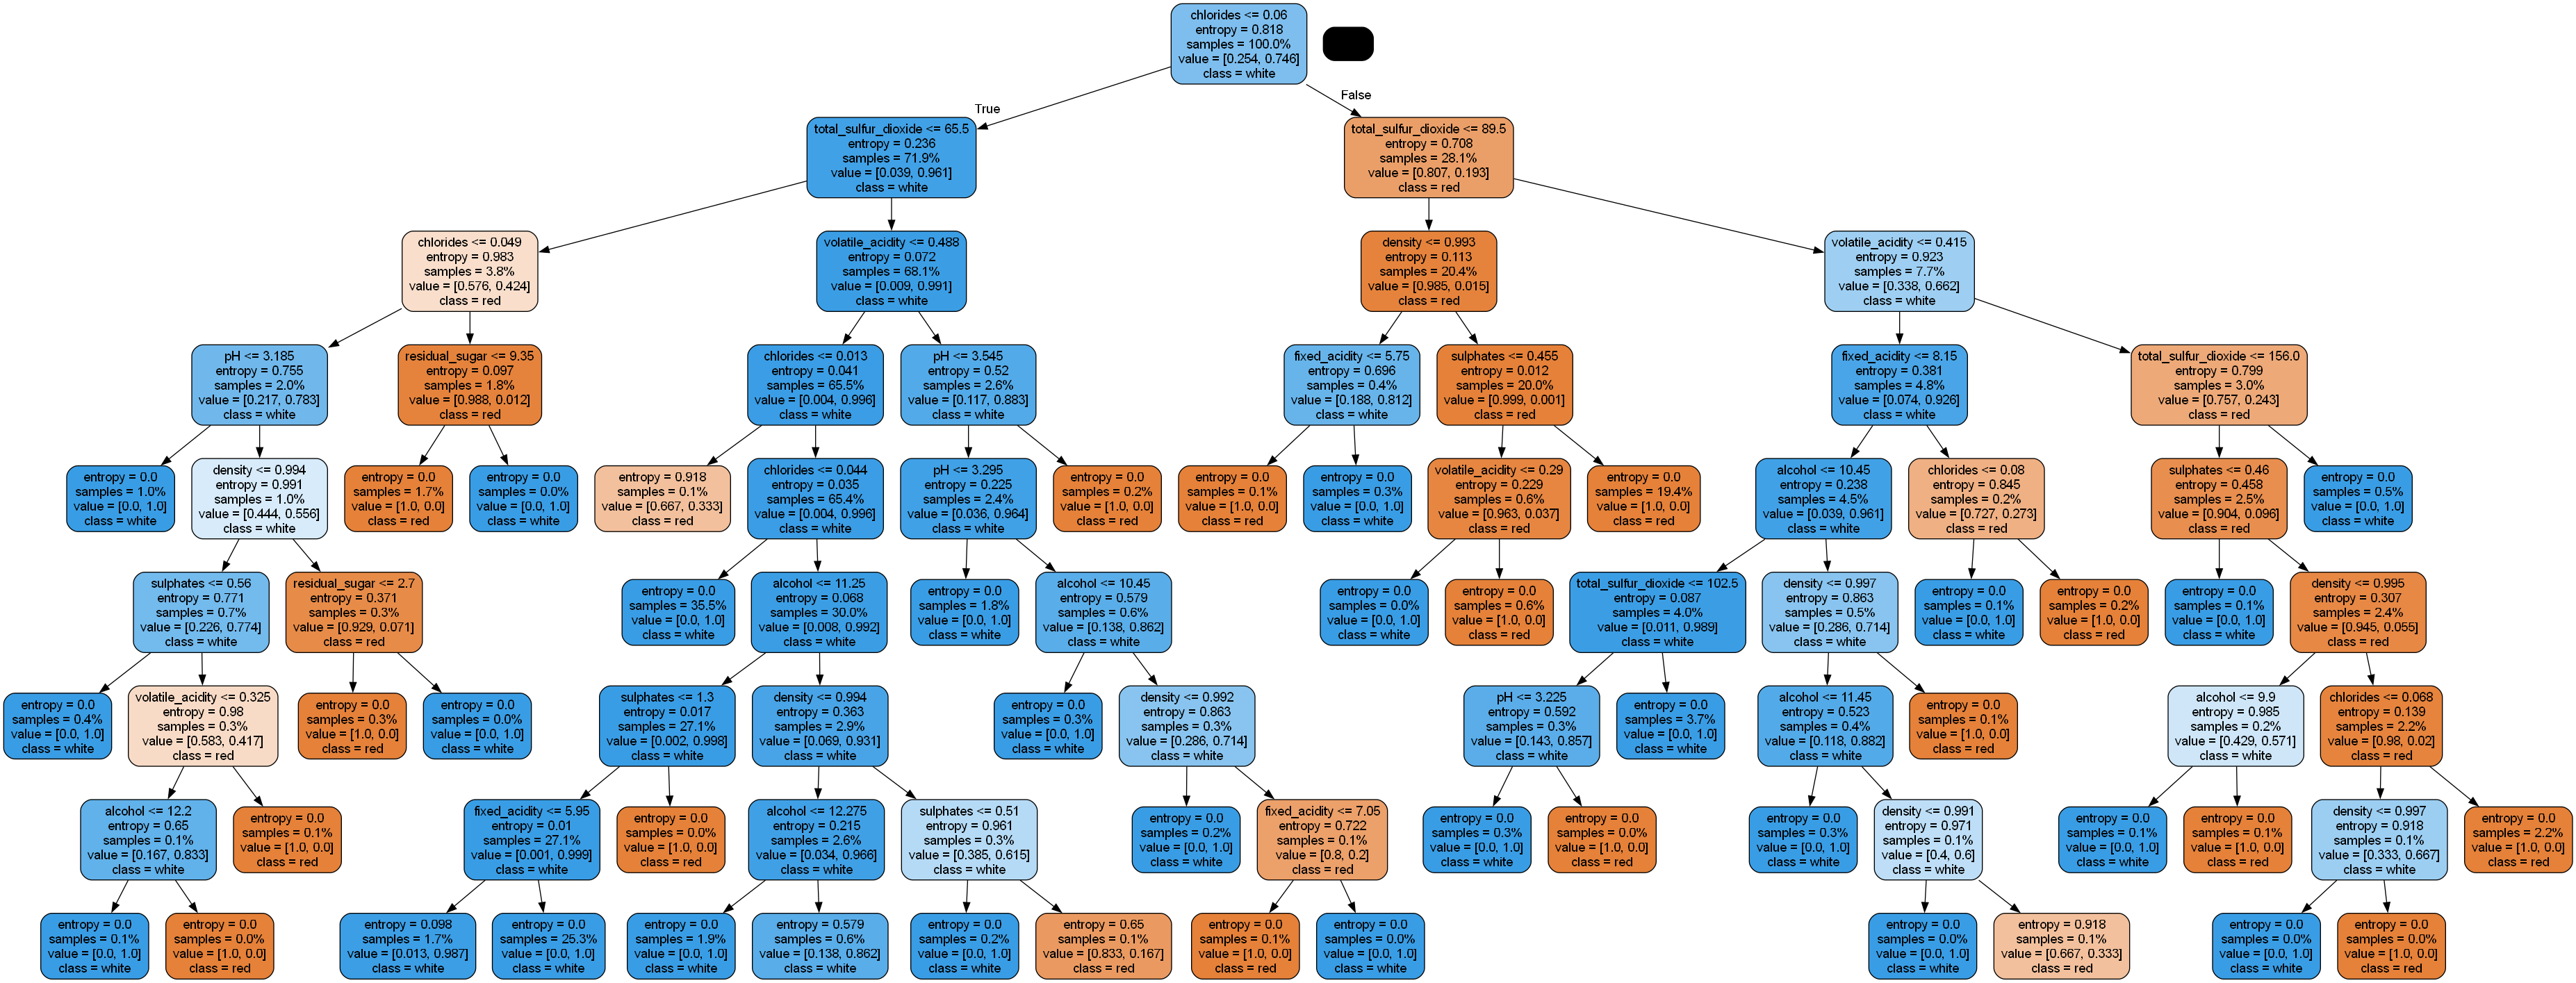

In [13]:
try:
    import pydotplus
    pydotplus_installed = True
except Exception:
    pydotplus_installed = False
    print("PyDotPlus не установлен - визуализация пропущена (pip install pydotplus).")

def tree_image(model, feature_names, class_names=("red", "white")):
    buf = StringIO()
    export_graphviz(model, out_file=buf, feature_names=feature_names, class_names=list(class_names),
                    filled=True, rounded=True, proportion=True)
    graph = pydotplus.graph_from_dot_data(buf.getvalue())
    return Image(graph.create_png())

graphviz_ok = False
if pydotplus_installed:
    try:
        display(tree_image(best_tree_clf, feature_cols))   # лучшее дерево Q4
        graphviz_ok = True
    except Exception as e:
        print("GraphViz недоступен или ошибка отрисовки:", type(e).__name__, e)

Дерево из Q3 (без ограничений):

Узлов в дереве Q3: 143 - полное изображение будет огромным; рисуем верхние уровни (max_depth=4) и сохраняем целиком в файл.


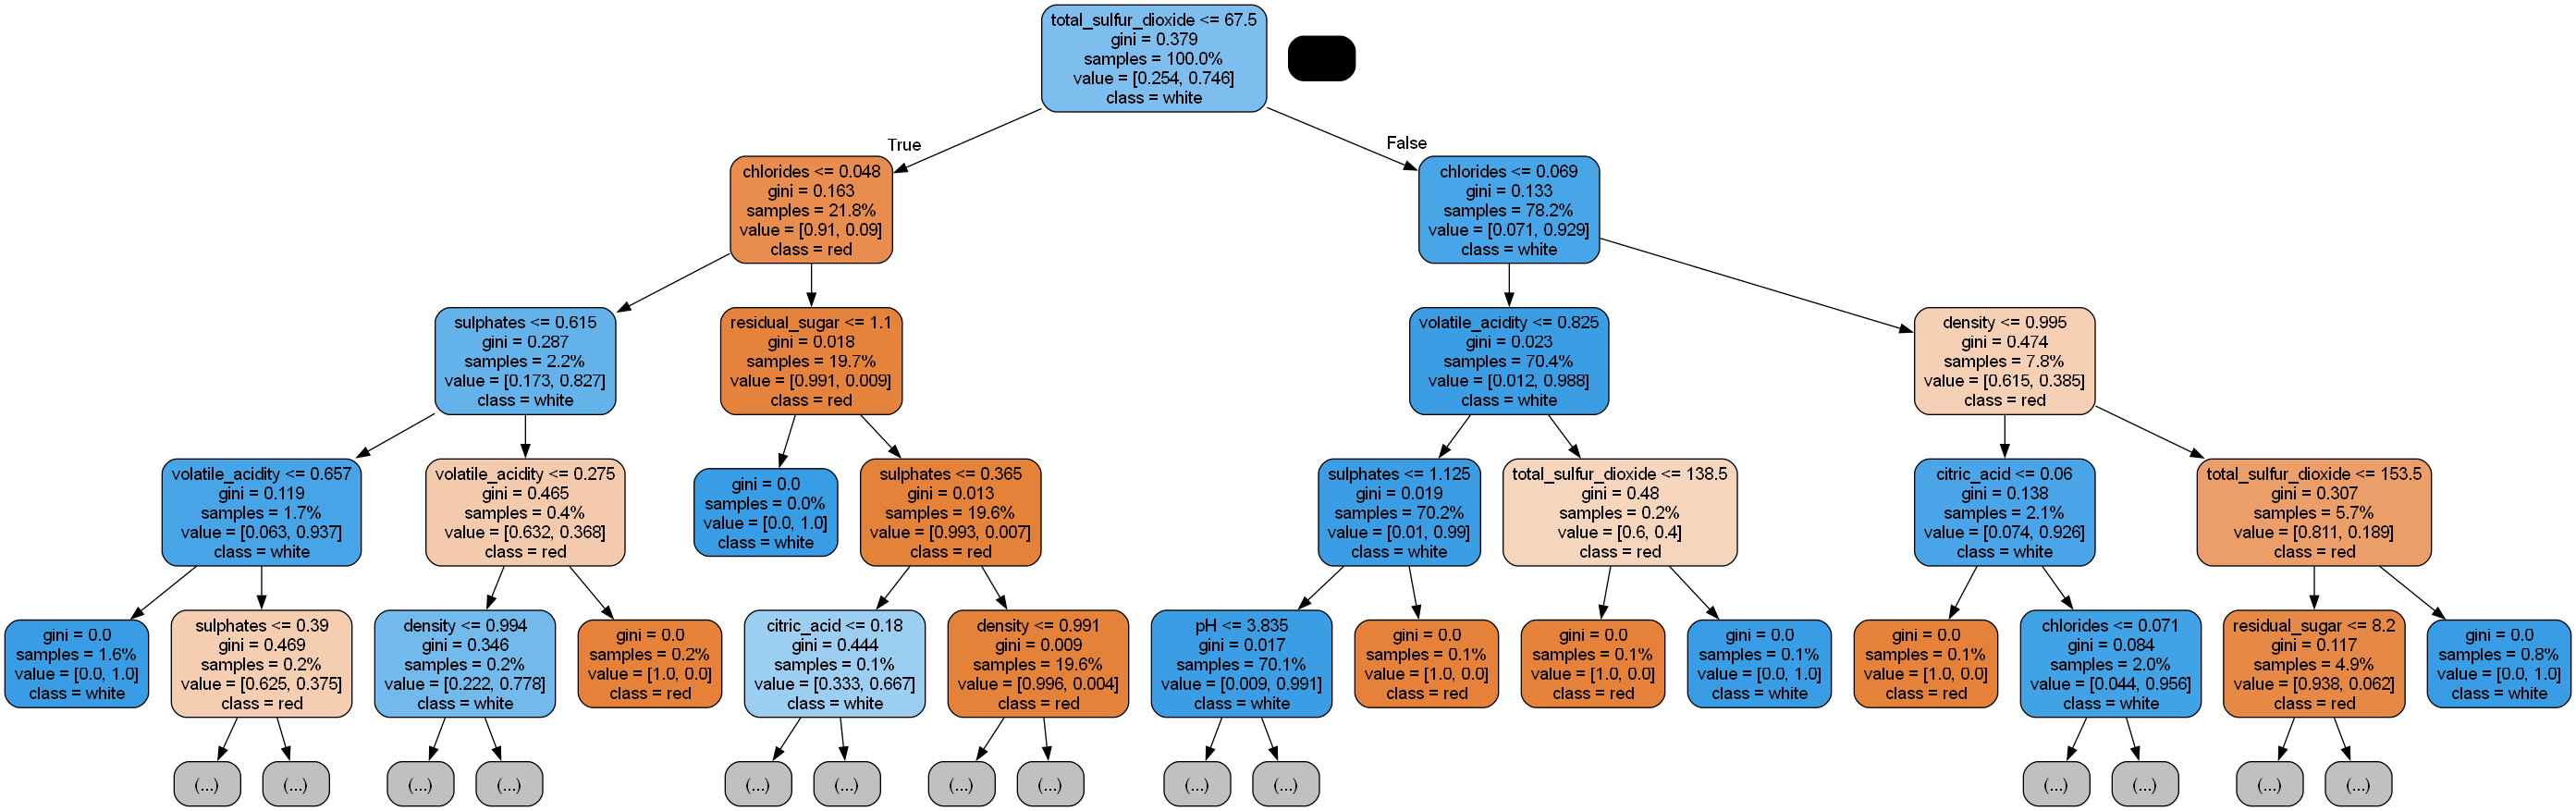

Полное дерево сохранено: tree_q3_full.png


In [14]:
if graphviz_ok:
    print("Узлов в дереве Q3:", dt.tree_.node_count, "- полное изображение будет огромным; рисуем верхние уровни (max_depth=4) и сохраняем целиком в файл.")
    buf = StringIO()
    export_graphviz(dt, out_file=buf, feature_names=feature_cols, class_names=["red","white"],
                    filled=True, rounded=True, proportion=True, max_depth=4)
    display(Image(pydotplus.graph_from_dot_data(buf.getvalue()).create_png()))
    buf = StringIO()
    export_graphviz(dt, out_file=buf, feature_names=feature_cols, class_names=["red","white"], filled=True, rounded=True)
    pydotplus.graph_from_dot_data(buf.getvalue()).write_png("tree_q3_full.png")
    print("Полное дерево сохранено: tree_q3_full.png")
else:
    print("Визуализация пропущена.")

Выше (первое изображение) - лучшее дерево из Q4. Дерево из Q5 не визуализируем из-за размера.

**Вывод.** Лучшее дерево Q4 (глубина 8) читается и интерпретируется; полное дерево Q3 (глубина 20) отрисовано только до 4 уровней, целиком сохранено в `tree_q3_full.png`. Верхние разбиения обоих деревьев используют одни и те же сильные признаки, а глубокие ветви Q3 в основном дочищают единичные нетипичные объекты - что и есть источник небольшого переобучения.

## Итог

**Сильные стороны деревьев на этом датасете:** очень высокая точность классификации цвета (≈98,4-98,5% на тесте) без масштабирования признаков; нелинейные зависимости находятся автоматически; модель интерпретируема (особенно неглубокая); работает и для классификации, и для регрессии сахара (R² ≈ 0,87 к константному прогнозу).

**Слабые стороны:** склонность к переобучению (идеальное запоминание train в Q3, MSE train/test = 0,60/2,70 в Q5); большой размер дерева регрессии (2109 узлов) делает его неинтерпретируемым; результаты чувствительны к разбиению (на тесте всего ~450 красных вин, разница в 3 объекта меняет метрики на 0,15 п.п.); дубликаты в данных могут завышать оценки. Ограничение глубины (Q4) сделало модель вдвое проще при той же точности, но не улучшило тест. Для дальнейшего улучшения стоит попробовать ансамбли (Random Forest, Gradient Boosting) или cost-complexity pruning (`ccp_alpha`).